# MDP & Q-Learning for Student Learning Optimization

Models a student's 120-minute study session as a **Markov Decision Process** and learns a study strategy with **tabular Q-learning**.

| MDP element | Implementation |
|---|---|
| **State** `s = (T, C, t)` | `T` = coverage vector (0/1), `C` = confidence vector in [0, 1], `t` = minutes remaining |
| **Actions** (per topic *i*) | `Study(i)` (15 min), `Revise(i)` (10 min), `PracticeTest(i)` (20 min) |
| **Transitions** | Stochastic changes to confidence; practice tests can raise confidence **or** reveal gaps and lower it |
| **Reward** | `λ1·CoverageGain + λ2·ConfidenceGain + λ3·ExpectedScoreGain − λ4·TimeCost` |
| **Exam score** | `0.4·Coverage + 0.4·AvgConfidence + 0.2·PracticeAccuracy` |
| **Termination** | Episode ends when no action fits in the remaining time |

**Different starting states.** The student does *not* always start fresh. `env.reset()` can start from:
* a **random** state (some topics already studied, varying confidence, an *overconfident* student, less than 120 min left), or
* a **custom** state you specify (see the "Try your own starting state" section).

**Valid actions** (action masking): `Study(i)` only for unstudied topics, `Revise(i)` only for studied topics, `PracticeTest(i)` for any topic (this lets a test catch overconfidence on an unstudied topic).

## 1. Setup & configuration

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from dataclasses import dataclass, field

SEED = 42
rng_global = np.random.default_rng(SEED)

@dataclass
class Config:
    topics: tuple = ("Algebra", "Geometry", "Probability", "Calculus")
    total_time: int = 120                     # minutes (study budget)
    time_cost: dict = field(default_factory=lambda: {"Study": 15, "Revise": 10, "Practice": 20})
    # reward weights  (λ1 coverage, λ2 confidence, λ3 exam score, λ4 time)
    lam1: float = 0.5
    lam2: float = 0.5
    lam3: float = 2.0
    lam4: float = 0.5
    # expected score weights
    w_cov: float = 0.4
    w_conf: float = 0.4
    w_prac: float = 0.2
    high_conf: float = 0.7                    # "high confidence" threshold (decision logic)
    # Q-learning hyper-parameters
    gamma: float = 0.95
    alpha: float = 0.1
    episodes: int = 60_000
    eps_start: float = 1.0
    eps_end: float = 0.05

cfg = Config()
N = len(cfg.topics)

# Action encoding: action = kind * N + topic     (kind: 0=Study, 1=Revise, 2=Practice)
KINDS = ["Study", "Revise", "Practice"]
N_ACTIONS = 3 * N

def action_name(a):
    kind, topic = divmod(a, N)
    label = "PracticeTest" if KINDS[kind] == "Practice" else KINDS[kind]
    return f"{label}({cfg.topics[topic]})"

print(f"{N} topics, {N_ACTIONS} actions, {cfg.total_time}-minute budget")

4 topics, 12 actions, 120-minute budget


## 2. The environment (MDP)

**Transition model** (hidden from the Q-learning agent, which only sees samples):

| Action | Outcome |
|---|---|
| `Study(i)` | Topic becomes covered. With prob. 0.85 confidence rises a lot (+0.30 to +0.50), otherwise only a little (+0.10 to +0.20). |
| `Revise(i)` | With prob. 0.90 closes 25–50% of the gap to full confidence, otherwise a tiny gain. |
| `PracticeTest(i)` | Pass probability = `0.15 + 0.80·confidence` if the topic is covered, only `0.10` if it is not. **Pass** → confidence +0.05 to +0.15, practice accuracy rises. **Fail** → gaps revealed, confidence drops (−0.10 to −0.25 if covered, −0.20 to −0.40 if the student was overconfident about an unstudied topic). |

**Practice accuracy** is tracked per topic (exponential moving average of test results, 0 if never tested) and averaged for the exam-score formula.

**Observation given to the agent:** `(T, discretised C, t, practice-accuracy level)`. Confidence is binned into low / medium / high (high is `> 0.7`, matching the decision logic), and practice accuracy into none / low / high. The small practice-accuracy level is an addition to the `(T, C, t)` state so the value of testing is visible to the agent.

In [ ]:
class StudyEnv:
    """Student-learning MDP.  State = (coverage T, confidence C, time left t, practice accuracy P)."""

    def __init__(self, cfg: Config, seed=None):
        self.cfg = cfg
        self.N = len(cfg.topics)
        self.rng = np.random.default_rng(seed)
        self.min_cost = min(cfg.time_cost.values())

    # ------------------------------------------------------------------ start states
    def random_start(self, p_fresh=0.25):
        """Sample a plausible starting state for a student."""
        N, r = self.N, self.rng
        if r.random() < p_fresh:                               # completely fresh student
            return dict(coverage=np.zeros(N), confidence=np.zeros(N),
                        practice_acc=np.zeros(N), time_left=self.cfg.total_time)
        cov = (r.random(N) < 0.4).astype(float)                # ~40% topics already studied
        conf = np.zeros(N)
        pacc = np.zeros(N)
        for i in range(N):
            if cov[i]:
                conf[i] = r.uniform(0.2, 0.95)
                if r.random() < 0.3:                           # has already taken a test on it
                    pacc[i] = np.clip(conf[i] + r.normal(0, 0.1), 0, 1)
            else:
                # mostly low confidence, sometimes OVERCONFIDENT about an unstudied topic
                conf[i] = r.uniform(0.7, 0.95) if r.random() < 0.2 else r.uniform(0.0, 0.3)
        t = int(r.choice(np.arange(15, self.cfg.total_time + 1, 5)))   # 15..120 min left
        return dict(coverage=cov, confidence=conf, practice_acc=pacc, time_left=t)

    def reset(self, start=None, random_start=True):
        """Reset to a given start state (dict) or a random one.  Fresh 120-min start if random_start=False."""
        N = self.N
        if start is None:
            start = self.random_start() if random_start else dict(
                coverage=np.zeros(N), confidence=np.zeros(N),
                practice_acc=np.zeros(N), time_left=self.cfg.total_time)
        self.T = np.array(start["coverage"], dtype=float)
        self.C = np.clip(np.array(start["confidence"], dtype=float), 0, 1)
        self.P = np.array(start.get("practice_acc", np.zeros(N)), dtype=float)
        self.t = int(start["time_left"])
        return self.observe()

    # ------------------------------------------------------------------ helpers
    def exam_score(self, T=None, C=None, P=None):
        T = self.T if T is None else T
        C = self.C if C is None else C
        P = self.P if P is None else P
        c = self.cfg
        return c.w_cov * T.mean() + c.w_conf * C.mean() + c.w_prac * P.mean()

    @staticmethod
    def conf_bin(c, hi):
        return 0 if c < 0.35 else (1 if c <= hi else 2)

    def observe(self):
        """Hashable, discretised state for the tabular agent."""
        hi = self.cfg.high_conf
        cb = tuple(self.conf_bin(c, hi) for c in self.C)
        pm = self.P.mean()
        pb = 0 if pm == 0 else (1 if pm < 0.5 else 2)
        return (tuple(int(x) for x in self.T), cb, self.t, pb)

    def action_cost(self, a):
        return self.cfg.time_cost[KINDS[a // self.N]]

    def valid_actions(self):
        acts = []
        for a in range(3 * self.N):
            kind, i = divmod(a, self.N)
            if self.action_cost(a) > self.t:                   # not enough time left
                continue
            if kind == 0 and self.T[i] == 1:                   # Study only unstudied topics
                continue
            if kind == 1 and self.T[i] == 0:                   # Revise only studied topics
                continue
            acts.append(a)
        return acts

    def is_done(self):
        return self.t < self.min_cost or len(self.valid_actions()) == 0

    # ------------------------------------------------------------------ dynamics
    def step(self, a):
        assert a in self.valid_actions(), f"Invalid action {action_name(a)} in current state"
        c, r = self.cfg, self.rng
        kind, i = divmod(a, self.N)
        cost = self.action_cost(a)

        old_cov, old_conf, old_score = self.T.mean(), self.C.mean(), self.exam_score()

        if kind == 0:                                          # ---- Study
            self.T[i] = 1
            gain = r.uniform(0.30, 0.50) if r.random() < 0.85 else r.uniform(0.10, 0.20)
            self.C[i] = min(1.0, self.C[i] + gain)
        elif kind == 1:                                        # ---- Revise
            if r.random() < 0.90:
                self.C[i] += (1 - self.C[i]) * r.uniform(0.25, 0.50)
            else:
                self.C[i] = min(1.0, self.C[i] + 0.02)
        else:                                                  # ---- PracticeTest
            if self.T[i] == 1:
                p_pass = 0.15 + 0.80 * self.C[i]
            else:
                p_pass = 0.10
            passed = r.random() < p_pass
            if passed:
                self.C[i] = min(1.0, self.C[i] + r.uniform(0.05, 0.15))
            elif self.T[i] == 1:
                self.C[i] = max(0.0, self.C[i] - r.uniform(0.10, 0.25))   # reveals gaps
            else:
                self.C[i] = max(0.0, self.C[i] - r.uniform(0.20, 0.40))   # corrects overconfidence
            self.P[i] = 0.5 * self.P[i] + 0.5 * float(passed)             # practice accuracy (EMA)

        self.t -= cost

        # ---- reward: λ1·CovGain + λ2·ConfGain + λ3·ScoreGain − λ4·TimeCost  (all normalised)
        cov_gain = self.T.mean() - old_cov
        conf_gain = self.C.mean() - old_conf
        score_gain = self.exam_score() - old_score
        time_cost = cost / c.total_time
        reward = (c.lam1 * cov_gain + c.lam2 * conf_gain
                  + c.lam3 * score_gain - c.lam4 * time_cost)

        done = self.is_done()
        return self.observe(), reward, done, dict(score=self.exam_score(), cost=cost)

    def describe(self):
        rows = [(n, int(self.T[k]), round(self.C[k], 2), round(self.P[k], 2))
                for k, n in enumerate(self.cfg.topics)]
        df = pd.DataFrame(rows, columns=["Topic", "Studied", "Confidence", "PracticeAcc"])
        return df, self.t, round(self.exam_score(), 3)


env = StudyEnv(cfg, seed=SEED)
env.reset(random_start=True)
df, t, score = env.describe()
print(f"Example random start  |  time left = {t} min  |  expected exam score = {score}")
df

Example random start  |  time left = 55 min  |  expected exam score = 0.227


,Topic,Studied,Confidence,PracticeAcc
0,Algebra,0,0.23,0.0
1,Geometry,0,0.04,0.0
2,Probability,0,0.11,0.0
3,Calculus,1,0.90,0.0


## 3. Baseline policies

* **Random** – picks any valid action.
* **Rule-based** – the *Decision Logic* from the model: work on the **weakest topic** (lowest confidence) first:
  * studied & confidence `> 0.7` → `PracticeTest`
  * not studied but confidence `> 0.7` → `PracticeTest` (validate / correct overconfidence)
  * not studied & low confidence → `Study`
  * studied & low confidence → `Revise`

  If the preferred action doesn't fit in the remaining time, it falls back to the next-best affordable action.

In [ ]:
def random_policy(env, obs=None):
    return int(env.rng.choice(env.valid_actions()))

def rule_based_policy(env, obs=None):
    valid = set(env.valid_actions())
    hi = env.cfg.high_conf
    order = np.argsort(env.C)                      # weakest topic first
    for i in order:
        if env.C[i] > hi:
            pref = [2 * N + i]                     # PracticeTest (validate / correct overconfidence)
        elif env.T[i] == 0:
            pref = [0 * N + i]                     # Study
        else:
            pref = [1 * N + i]                     # Revise
        for a in pref:
            if a in valid:
                return a
    return min(valid, key=env.action_cost)         # nothing preferred fits -> cheapest valid action

## 4. Q-learning

When transition probabilities are unknown the agent learns from sampled experience:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\right]$$

* **Every episode starts from a different state** (`env.reset(random_start=True)`), so the learned policy covers fresh students, half-prepared students, overconfident students and students with little time left.
* ε-greedy exploration with linear decay; `max` is taken only over *valid* actions at `s'`.
* For states never visited in training, the agent falls back to the rule-based policy.

In [ ]:
class QAgent:
    def __init__(self, cfg: Config, seed=0):
        self.cfg = cfg
        self.Q = defaultdict(lambda: np.zeros(N_ACTIONS))
        self.rng = np.random.default_rng(seed)

    def best_valid(self, obs, valid):
        q = self.Q[obs]
        return max(valid, key=lambda a: q[a])

    def act(self, env, obs, eps=0.0):
        valid = env.valid_actions()
        if self.rng.random() < eps:
            return int(self.rng.choice(valid))
        if obs not in self.Q:                          # unseen state -> fall back to rule-based logic
            return rule_based_policy(env)
        return self.best_valid(obs, valid)

    def train(self, env, episodes=None, log_every=5000):
        c = self.cfg
        episodes = episodes or c.episodes
        returns = []
        for ep in range(episodes):
            eps = max(c.eps_end, c.eps_start - (c.eps_start - c.eps_end) * ep / (0.8 * episodes))
            obs = env.reset(random_start=True)             # <-- different start state every episode
            total, done = 0.0, env.is_done()
            while not done:
                a = self.act(env, obs, eps)
                nobs, r, done, _ = env.step(a)
                if done:
                    target = r
                else:
                    nxt = env.valid_actions()
                    target = r + c.gamma * max(self.Q[nobs][x] for x in nxt)
                self.Q[obs][a] += c.alpha * (target - self.Q[obs][a])
                obs, total = nobs, total + r
            returns.append(total)
            if (ep + 1) % log_every == 0:
                print(f"episode {ep+1:>6}  eps={eps:.2f}  avg return (last {log_every}) = "
                      f"{np.mean(returns[-log_every:]):+.3f}   |Q| states = {len(self.Q):,}")
        return returns

agent = QAgent(cfg, seed=SEED)
train_env = StudyEnv(cfg, seed=SEED)
returns = agent.train(train_env)

episode   5000  eps=0.90  avg return (last 5000) = +0.366   |Q| states = 9,186


episode  10000  eps=0.80  avg return (last 5000) = +0.454   |Q| states = 13,601


episode  15000  eps=0.70  avg return (last 5000) = +0.553   |Q| states = 16,552


episode  20000  eps=0.60  avg return (last 5000) = +0.629   |Q| states = 18,682


episode  25000  eps=0.51  avg return (last 5000) = +0.719   |Q| states = 20,331


episode  30000  eps=0.41  avg return (last 5000) = +0.767   |Q| states = 21,575


... (2 outputs left out)

episode  45000  eps=0.11  avg return (last 5000) = +0.935   |Q| states = 24,104


episode  50000  eps=0.05  avg return (last 5000) = +0.965   |Q| states = 24,611


episode  55000  eps=0.05  avg return (last 5000) = +0.977   |Q| states = 25,020


episode  60000  eps=0.05  avg return (last 5000) = +0.966   |Q| states = 25,440


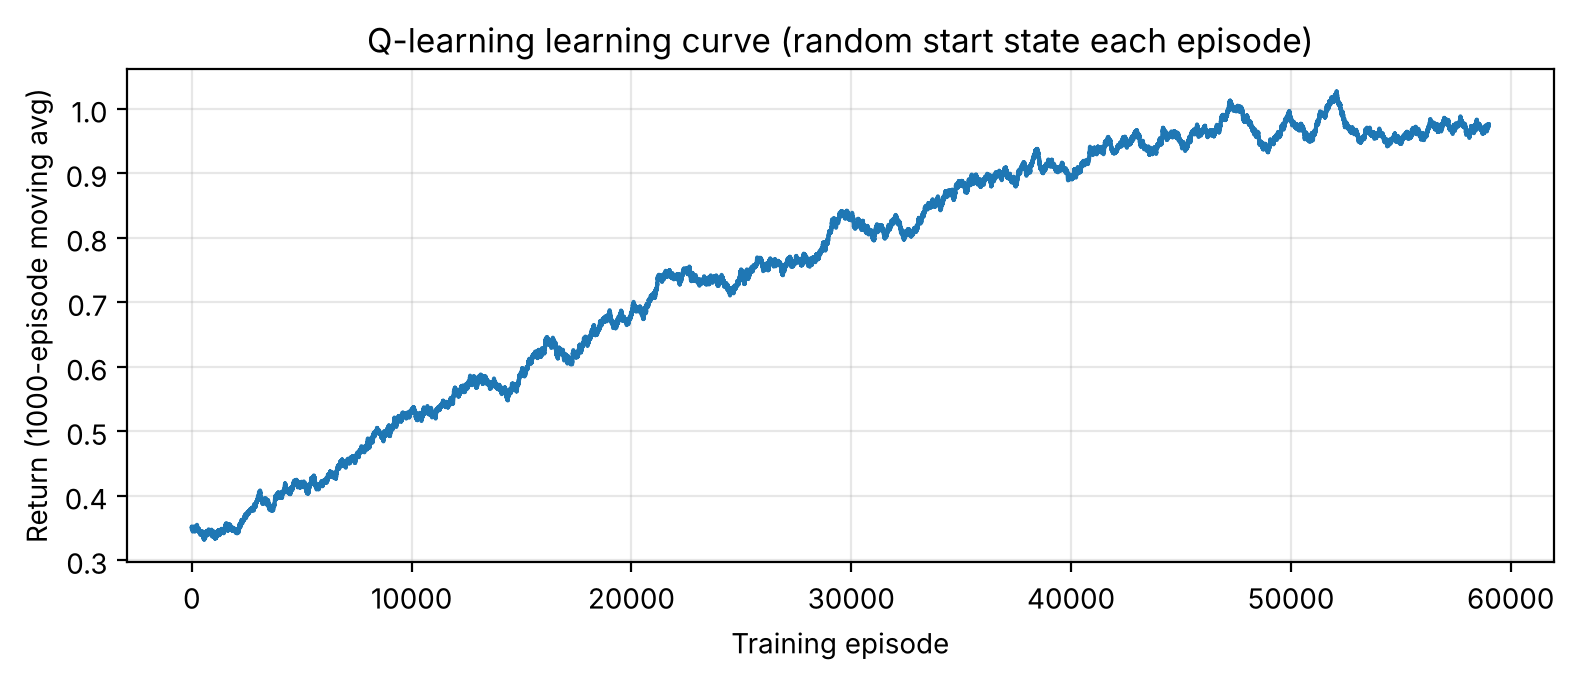

In [ ]:
# Learning curve
w = 1000
smooth = np.convolve(returns, np.ones(w) / w, mode="valid")
plt.figure(figsize=(8, 3.5))
plt.plot(smooth)
plt.xlabel("Training episode"); plt.ylabel(f"Return ({w}-episode moving avg)")
plt.title("Q-learning learning curve (random start state each episode)")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 5. Evaluation from many different starting states

All policies are evaluated on the **same set of 500 random start states** (same seeds, fresh stochastic transitions for each rollout). We report cumulative reward and the **gain in expected exam score** (final − initial).

In [ ]:
def rollout(policy, start, seed, verbose=False):
    e = StudyEnv(cfg, seed=seed)
    obs = e.reset(start=start)
    s0 = e.exam_score()
    ret, done, log = 0.0, e.is_done(), []
    while not done:
        a = policy(e, obs)
        t_before = e.t
        obs, r, done, info = e.step(a)
        ret += r
        log.append((t_before, action_name(a), round(r, 3), round(info["score"], 3)))
    return ret, s0, e.exam_score(), log

def evaluate(policy, n_starts=500, seed=123):
    gen = StudyEnv(cfg, seed=seed)                      # generates the start states
    rows = []
    for k in range(n_starts):
        start = gen.random_start()
        ret, s0, s1, _ = rollout(policy, start, seed=10_000 + k)
        rows.append((ret, s0, s1, s1 - s0, start["time_left"]))
    return pd.DataFrame(rows, columns=["return", "initial_score", "final_score", "score_gain", "start_time"])

policies = {
    "Random": random_policy,
    "Rule-based": rule_based_policy,
    "Q-learning": lambda e, obs: agent.act(e, obs, eps=0.0),
}
results = {name: evaluate(p) for name, p in policies.items()}

summary = pd.DataFrame({
    name: dict(mean_return=df["return"].mean(),
               mean_final_score=df["final_score"].mean(),
               mean_score_gain=df["score_gain"].mean())
    for name, df in results.items()
}).T.round(3)
summary

,mean_return,mean_final_score,mean_score_gain
Random,0.320,0.446,0.203
Rule-based,0.943,0.634,0.392
Q-learning,1.017,0.657,0.414


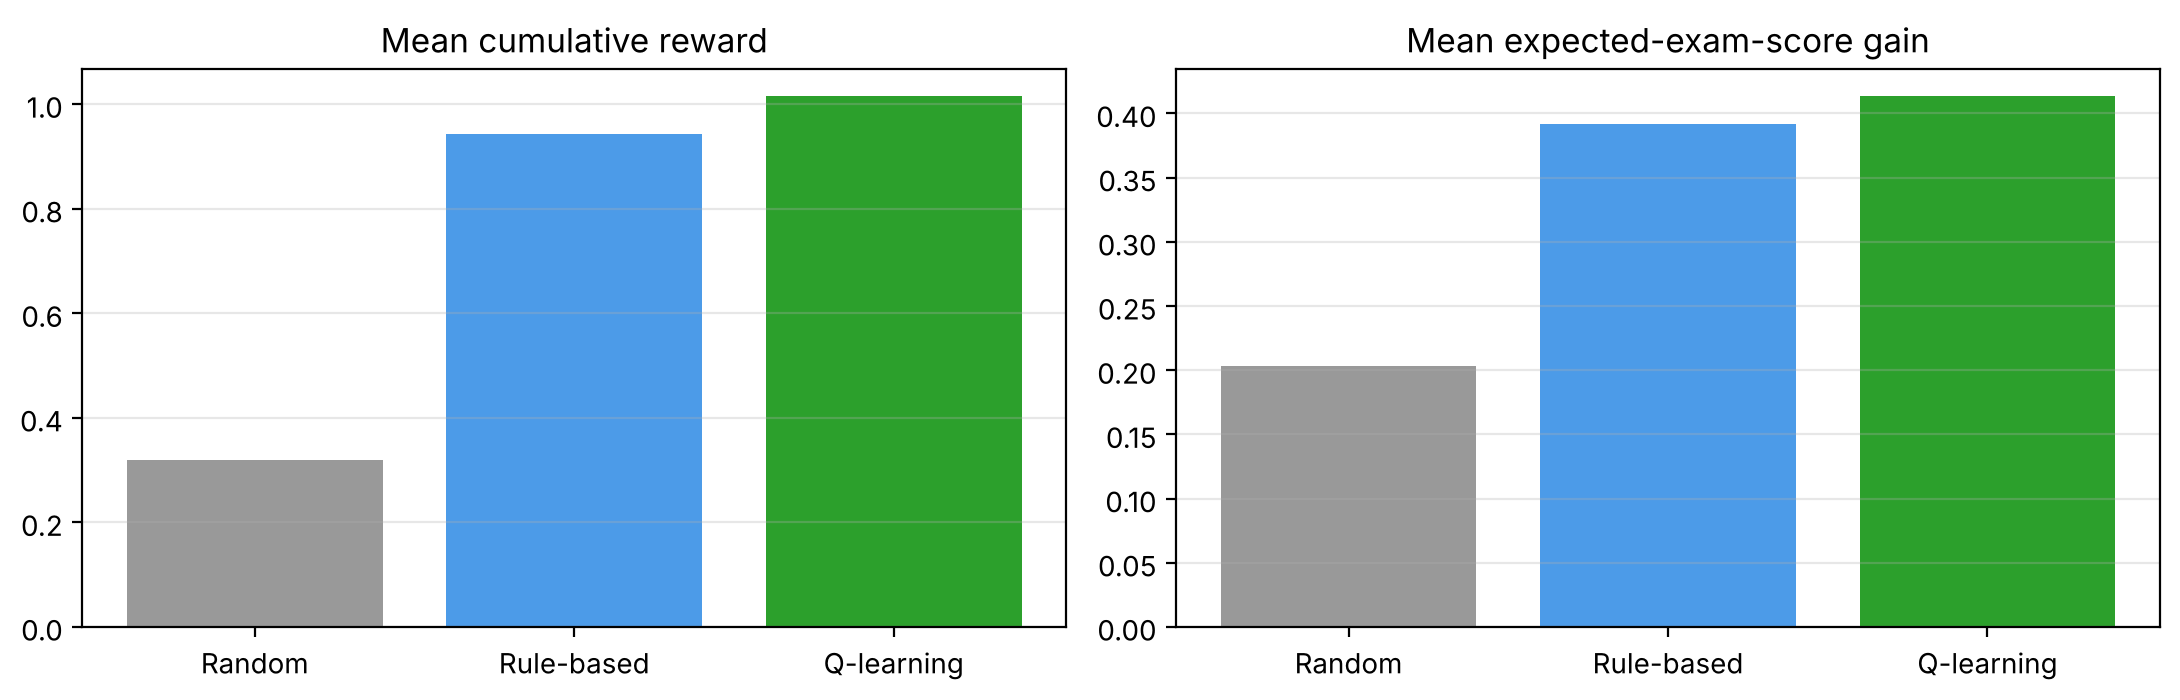

Mean score gain by starting time budget:


,Random,Rule-based,Q-learning
start_time,,,
15-45 min,0.076,0.217,0.224
50-90 min,0.152,0.318,0.357
95-120 min,0.307,0.537,0.556


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
names = list(results)
ax[0].bar(names, [results[n]["return"].mean() for n in names], color=["#999", "#4c9be8", "#2ca02c"])
ax[0].set_title("Mean cumulative reward"); ax[0].grid(axis="y", alpha=.3)
ax[1].bar(names, [results[n]["score_gain"].mean() for n in names], color=["#999", "#4c9be8", "#2ca02c"])
ax[1].set_title("Mean expected-exam-score gain"); ax[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

# Performance by how much time the student starts with
bins = pd.cut(results["Q-learning"]["start_time"], [0, 45, 90, 120], labels=["15-45 min", "50-90 min", "95-120 min"])
by_time = pd.DataFrame({n: results[n].groupby(bins, observed=True)["score_gain"].mean() for n in names}).round(3)
print("Mean score gain by starting time budget:")
by_time

## 6. Try your own starting state

Describe **where the student currently is** and get the recommended next action plus a full simulated study plan.

* `coverage` – 1 if the topic has been studied, else 0
* `confidence` – current confidence per topic (0 to 1)
* `time_left` – minutes remaining (≤ 120)
* `practice_acc` – optional, past practice-test accuracy per topic

In [ ]:
def recommend(start, policy_name="Q-learning", seed=0, show_plan=True):
    # recommended action = what the policy would do right now
    e = StudyEnv(cfg, seed=seed)
    obs = e.reset(start=start)
    df, t, score = e.describe()
    print(f"Starting state  |  time left = {t} min  |  expected exam score = {score}")
    display(df)
    if e.is_done():
        print("Not enough time left for any action."); return
    first = policies[policy_name](e, obs)
    print(f"\n{policy_name} recommends next:  {action_name(first)}  ({e.action_cost(first)} min)")
    if show_plan:
        ret, s0, s1, log = rollout(policies[policy_name], start, seed=seed)
        plan = pd.DataFrame(log, columns=["time_left_before", "action", "reward", "score_after"])
        print(f"\nSimulated plan (one stochastic run):  score {s0:.3f} -> {s1:.3f},  return = {ret:+.3f}")
        display(plan)

# (a) Fresh student, full 120 minutes
recommend(dict(coverage=[0, 0, 0, 0], confidence=[0, 0, 0, 0], time_left=120))

Starting state  |  time left = 120 min  |  expected exam score = 0.0


,Topic,Studied,Confidence,PracticeAcc
0,Algebra,0,0.0,0.0
1,Geometry,0,0.0,0.0
2,Probability,0,0.0,0.0
3,Calculus,0,0.0,0.0



Q-learning recommends next:  Study(Algebra)  (15 min)

Simulated plan (one stochastic run):  score 0.000 -> 0.663,  return = +1.656


,time_left_before,action,reward,score_after
0,120,Study(Algebra),0.378,0.135
1,105,Study(Probability),0.361,0.266
2,90,Study(Calculus),0.419,0.414
3,75,Study(Geometry),0.407,0.559
4,60,Revise(Algebra),0.060,0.590
5,50,Revise(Probability),0.015,0.607
6,40,Revise(Probability),0.002,0.621
7,30,Revise(Probability),-0.005,0.632
8,20,Revise(Algebra),0.000,0.645
9,10,Revise(Calculus),0.018,0.663


In [ ]:
# (b) Partially prepared student with only 60 minutes left
recommend(dict(coverage=[1, 1, 0, 0], confidence=[0.8, 0.4, 0.1, 0.0],
               practice_acc=[0.7, 0, 0, 0], time_left=60))

Starting state  |  time left = 60 min  |  expected exam score = 0.365


,Topic,Studied,Confidence,PracticeAcc
0,Algebra,1,0.8,0.7
1,Geometry,1,0.4,0.0
2,Probability,0,0.1,0.0
3,Calculus,0,0.0,0.0



Q-learning recommends next:  Revise(Algebra)  (10 min)

Simulated plan (one stochastic run):  score 0.365 -> 0.701,  return = +0.842


,time_left_before,action,reward,score_after
0,60,Revise(Algebra),-0.021,0.371
1,50,Study(Probability),0.361,0.502
2,35,Study(Calculus),0.419,0.650
3,20,Revise(Geometry),0.043,0.676
4,10,Revise(Calculus),0.040,0.701


In [ ]:
# (c) Overconfident student: has NOT studied Probability but thinks they know it (confidence 0.9)
recommend(dict(coverage=[1, 1, 0, 1], confidence=[0.75, 0.5, 0.9, 0.3], time_left=90))

Starting state  |  time left = 90 min  |  expected exam score = 0.545


,Topic,Studied,Confidence,PracticeAcc
0,Algebra,1,0.75,0.0
1,Geometry,1,0.50,0.0
2,Probability,0,0.90,0.0
3,Calculus,1,0.30,0.0



Q-learning recommends next:  Study(Probability)  (15 min)

Simulated plan (one stochastic run):  score 0.545 -> 0.765,  return = +0.330


,time_left_before,action,reward,score_after
0,90,Study(Probability),0.295,0.655
1,75,PracticeTest(Geometry),-0.017,0.685
2,55,Revise(Geometry),0.028,0.707
3,45,Revise(Calculus),0.057,0.737
4,35,Revise(Algebra),-0.002,0.749
5,25,Revise(Geometry),-0.023,0.755
6,15,Revise(Calculus),-0.008,0.765


In [ ]:
# (d) Compare all three policies on the same custom start (averaged over 300 stochastic runs)
custom = dict(coverage=[1, 0, 0, 1], confidence=[0.6, 0.1, 0.85, 0.75], time_left=75)
rows = {}
for name, p in policies.items():
    out = [rollout(p, custom, seed=s) for s in range(300)]
    rows[name] = dict(mean_return=np.mean([o[0] for o in out]),
                      final_score=np.mean([o[2] for o in out]),
                      score_gain=np.mean([o[2] - o[1] for o in out]))
pd.DataFrame(rows).T.round(3)

,mean_return,final_score,score_gain
Random,0.125,0.571,0.141
Rule-based,0.351,0.642,0.212
Q-learning,0.652,0.721,0.291


## 7. Notes & customisation

* **Topics / budget:** edit `Config.topics`, `total_time`, `time_cost`. More topics means a larger state space, so increase `episodes` (or switch to function approximation / DQN).
* **Reward trade-offs:** change `lam1…lam4` to favour breadth of coverage, depth of confidence, exam score, or time efficiency.
* **Transition probabilities:** the numbers in `StudyEnv.step` are illustrative. Replace them with estimates from real student data; the Q-learning code doesn't need to change because it only uses sampled transitions.
* **Starting states:** `StudyEnv.random_start()` controls the distribution of start states used for training (fresh vs. partly-prepared vs. overconfident students). Adjust `p_fresh` or the sampling rules to match your target population.
* **Unseen states:** states never visited in training fall back to the rule-based decision logic.